In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# สร้าง grayscale 10x10 metrix สุ่ม 0-255
grayscale_matrix_uint8 = np.random.randint(0, 256, size=(10, 10), dtype=np.uint8)
grayscale_matrix_int32 = np.random.randint(0, 256, size=(10, 10), dtype=np.int32)
grayscale_matrix_float32 = np.random.uniform(0.0, 255.0, size=(10, 10)).astype(np.float32)

def display_grayscale_matrix(matrix, title):
    print(title + " " + str(matrix.ndim) + " " + str(matrix.shape) + " " + str(matrix.dtype))
    print(matrix)
    print()

display_grayscale_matrix(grayscale_matrix_uint8, "Grayscale Matrix (uint8):")
display_grayscale_matrix(grayscale_matrix_int32, "Grayscale Matrix (int32):")
display_grayscale_matrix(grayscale_matrix_float32, "Grayscale Matrix (float32):")

Grayscale Matrix (uint8): 2 (10, 10) uint8
[[124 203  78 228  66  22 111 134  73 194]
 [182  86 247   7 239 250 105  12   5 161]
 [124   0 249 156 159  11  54 175  98  77]
 [ 92  73  85 209 126 247  74  39 136 152]
 [ 73 164 203 224 174 185 191 173 243 168]
 [  6  42 241   1 181  75 203 127  15 254]
 [221 254  16  72 131 199 150 124 156 243]
 [  0 167  74  69  75 141 227 231 208 237]
 [116 188 159  64 175 241  76  25 182 114]
 [ 36  88 195 153  45   0 120   7 240 152]]

Grayscale Matrix (int32): 2 (10, 10) int32
[[221 194  62  30 184 228  17 242 191 217]
 [ 27  65 216  87 190 104  48 178 156  66]
 [ 85 249  67 182  63  14 118 118 161  52]
 [216 191 136 231 188  65 201 238  35 121]
 [ 58   5 250 250 154  18 235 114  60 191]
 [113 138  36 192 197 160 189 194 239 115]
 [190 184 252 167 148 224 107  77  60 199]
 [ 37  40 172 208  39 253 161 183 154 108]
 [ 45 125 243 254 243  98 164 209  52  73]
 [ 29 155 129 198  72  11 230 136 193 213]]

Grayscale Matrix (float32): 2 (10, 10) float32
[[1

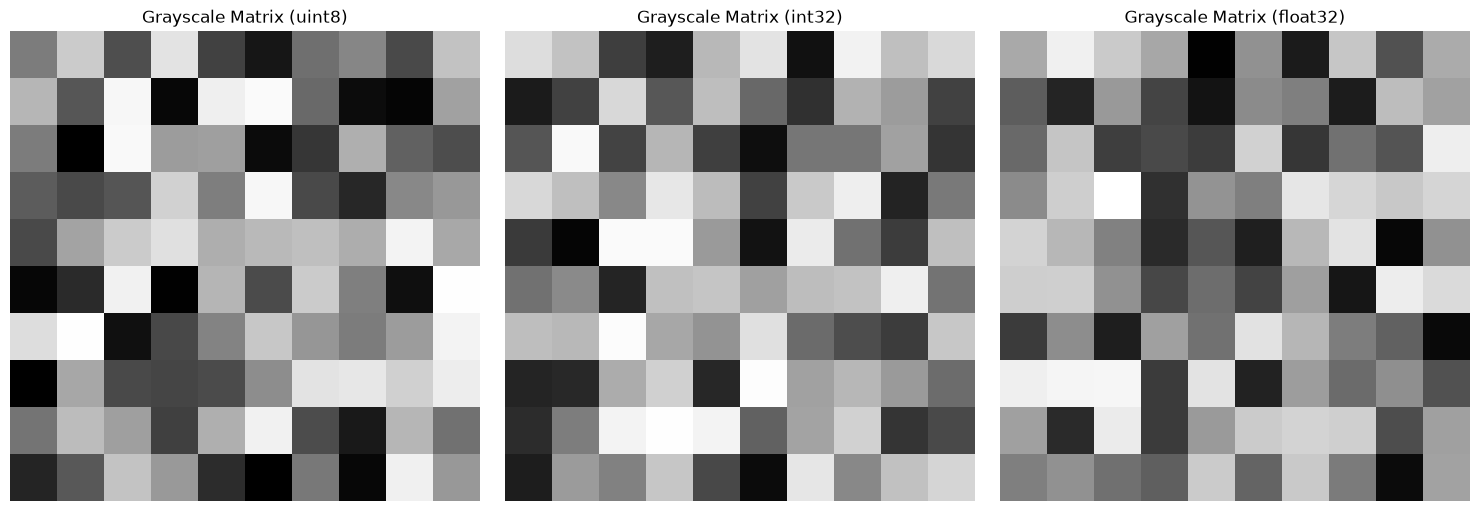

In [5]:
grayscale_matrix_set = [
    (grayscale_matrix_uint8, "Grayscale Matrix (uint8)"),
    (grayscale_matrix_int32, "Grayscale Matrix (int32)"), 
    (grayscale_matrix_float32, "Grayscale Matrix (float32)")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (grayscale_matrix, title) in zip(axes, grayscale_matrix_set):
    im = ax.imshow(grayscale_matrix, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

### np.uint8 เป็น default pixel
- เซนเซอร์กล้องส่วนใหญ่แปลงสัญญาณแสงเป็นสัญญาณดิจิทัลแบบ 8 บิตต่อช่องสัญญาณสี
- จอภาพและระบบสี sRGB ประมวลผลบนพื้นฐาน 8 บิต

### np.float32 เพื่อ นำเข้าแบบจำลองทางคณิตศาสตร์
- ป้องกันปัญหา Overflow และ Underflow ทำให้การคำนวณ Derivative, Convolution และ Gradient ไม่เกิดข้อผิดพลาด
- รองรับทศนิยมและการปรับมาตรฐาน (Normalization)
- ความเร็วในการประมวลผลบน GPU

In [6]:
p1 = np.array([250], dtype=np.uint8)
p2 = np.array([5], dtype=np.uint8)

print("uint8")
overflow_uint8 = p1 + 10
print("Overflow in uint8 (250 + 10):", overflow_uint8)

underflow_uint8 = p2 - 20
print("Underflow in uint8 (5 - 10):", underflow_uint8)

print("\nfloat32")
p1_float = p1.astype(np.float32)
p2_float = p2.astype(np.float32)

add_p1 = p1_float + 10
print("Addition in float32 (250 + 10):", add_p1)

sub_p2 = p2_float - 20
print("Subtraction in float32 (5 - 20):", sub_p2)

print("\nclip")
clip_add = np.clip(add_p1, 0, 255).astype(np.uint8)
print("Clipped Addition (250 + 10):", clip_add)

clip_sub = np.clip(sub_p2, 0, 255).astype(np.uint8)
print("Clipped Subtraction (5 - 20):", clip_sub)

uint8
Overflow in uint8 (250 + 10): [4]
Underflow in uint8 (5 - 10): [241]

float32
Addition in float32 (250 + 10): [260.]
Subtraction in float32 (5 - 20): [-15.]

clip
Clipped Addition (250 + 10): [255]
Clipped Subtraction (5 - 20): [0]


In [7]:
flat_pixels = np.random.rand(784)
print(f"Flat Pixels 1D : shape = {flat_pixels.shape}, size = {flat_pixels.size}")

image2d = flat_pixels.reshape((28, 28))
print(f"Image 2D : shape = {image2d.shape}, size = {image2d.size}")

sample_data = np.array([1, 2, 3, 4])

arr_inplace = sample_data.copy()
arr_inplace.resize((6,), refcheck=False)

arr_function = np.resize(sample_data, (6,))

print("\nIn-place resize: 4 -> 6", arr_inplace)
print("Function resize: 4 -> 6", arr_function)

arr_shrink = sample_data.copy()
arr_shrink.resize((2,), refcheck=False)
arr_shrink_function = np.resize(sample_data, (2,))
print("\nIn-place shrink: 4 -> 2", arr_shrink)
print("Function shrink: 4 -> 2", arr_shrink_function)   



Flat Pixels 1D : shape = (784,), size = 784
Image 2D : shape = (28, 28), size = 784

In-place resize: 4 -> 6 [1 2 3 4 0 0]
Function resize: 4 -> 6 [1 2 3 4 1 2]

In-place shrink: 4 -> 2 [1 2]
Function shrink: 4 -> 2 [1 2]


### ndarray.resize() (Method)
- ทำงานบนตัวแปรเดิม (In-place, คืนค่า None)
- เมื่อขยายขนาด (ขยายมิติ)	เติมเต็มตำแหน่งที่เพิ่มด้วย 0
- เมื่อลดขนาด	ตัดสมาชิกส่วนเกินทิ้งทันทีในอาเรย์เดิม
- ข้อจำกัด	หากอาร์เรย์มีการแชร์หน่วยความจำ (view) ต้องระบุ refcheck=False

### np.resize() (Function)
- สร้างและคืนค่าอาร์เรย์ชุดใหม่ (Copy)
- เมื่อขยายขนาด (ขยายมิติ) นำข้อมูลชุดเดิมมา วนซ้ำ (Repeat / Tile)
- เมื่อลดขนาด ตัดสมาชิกส่วนเกินทิ้งและคืนค่าตัวใหม่

In [13]:
image_with_channel = np.expand_dims(image2d, axis=-1)
print(f"เพิ่ม Channel (Grayscale): shape = {image_with_channel.shape}")

batch_input = np.expand_dims(image_with_channel, axis=0)
print(f"เพิ่ม Batch Dimension:     shape = {batch_input.shape}")

เพิ่ม Channel (Grayscale): shape = (28, 28, 1)
เพิ่ม Batch Dimension:     shape = (1, 28, 28, 1)


### การขยายมิติสำหรับ Deep Learning (np.expand_dims)
- เพิ่ม Channel (28, 28, 1): TensorFlow/Keras หรือ PyTorch มักต้องการมิติ Channel เสมอ สำหรับภาพขาวดำ (Grayscale) จำเป็นต้องมีขนาด 1 แชนแนล โดยระบุ axis=-1 (หรือ axis=2)
- เพิ่ม Batch Size (1, 28, 28, 1): Convolutional Neural Networks (CNN) รับข้อมูลเข้าเป็นแบทช์ในรูปแบบ (Batch, Height, Width, Channels)

In [16]:
# จำลองวัตถุสี่เหลี่ยมสว่าง (ค่าสูง) อยู่บนพื้นหลังมืด (ค่าต่ำ)
Q = np.array([
    [10,  12,  10,  15,  12,  10,  14,  11],
    [11,  15, 200, 205, 210, 200,  15,  10],
    [10,  14, 205, 255, 250, 205,  12,  13],
    [12,  13, 200, 250, 255, 200,  11,  10],
    [15,  10, 202, 204, 201, 200,  14,  12],
    [10,  11,  12,  15,  10,  13,  11,  10],
    [13,  10,  14,  11,  12,  10,  15,  11],
    [11,  12,  10,  13,  10,  14,  12,  10]
], dtype=np.uint8)

print(f"ขนาดภาพตั้งต้น: {Q.shape}")
print("ภาพต้นฉบับ 8x8:\n", Q)

sub_region = Q[1:4, 2:6]
print(f"\nขนาดพื้นที่ย่อย (Sub-region): {sub_region.shape}")
print("ผลลัพธ์จากการ Slice (Q[1:4, 2:6]):\n", sub_region)

ขนาดภาพตั้งต้น: (8, 8)
ภาพต้นฉบับ 8x8:
 [[ 10  12  10  15  12  10  14  11]
 [ 11  15 200 205 210 200  15  10]
 [ 10  14 205 255 250 205  12  13]
 [ 12  13 200 250 255 200  11  10]
 [ 15  10 202 204 201 200  14  12]
 [ 10  11  12  15  10  13  11  10]
 [ 13  10  14  11  12  10  15  11]
 [ 11  12  10  13  10  14  12  10]]

ขนาดพื้นที่ย่อย (Sub-region): (3, 4)
ผลลัพธ์จากการ Slice (Q[1:4, 2:6]):
 [[200 205 210 200]
 [205 255 250 205]
 [200 250 255 200]]


หลักการของ Roberts: การรับรู้ของเครื่องจักร ไม่สามารถวิเคราะห์ภาพทั้งผืนพร้อมกันในระดับโกลบอลได้ทันที แต่ต้องเริ่มต้นจาก ระดับจำเพาะที่ (Local Neighborhood) เพื่อตรวจจับความเปลี่ยนแปลงของระดับความเข้มแสง

เมื่อทำ Slicing เพื่อหาขอบและมุมได้ครบทุกจุดย่อย ข้อมูลเชิงสถิติจะถูกเชื่อมโยงเป็นเส้นโครงร่างร่างแห (Wireframe Representation)

อัลกอริทึมจำแนกได้ว่า กลุ่มพิกเซลค่าสูงภายในกรอบคือเนื้อวัตถุ (Figure) และ พิกเซลภายนอกคือระนาบพื้นหลัง (Ground) ซึ่งเป็นจุดเริ่มต้นของกระบวนการ Segmentation ในระบบภาพยุคปัจจุบัน